# Sequence models

This notebook trains three deep sequence models for remaining useful life (RUL) on NASA C-MAPSS FD001: a long short-term memory network (LSTM), a temporal convolutional network (TCN) and a Transformer encoder. Unlike the Phase 1 models, which read one row of features per cycle, these models read the raw history directly: a window of the last 30 cycles of sensor readings. Each model is tuned with the same five engine-grouped folds as Phase 1, so its cross-validation error sits directly next to the Phase 1 results. Only the training trajectories are used here.

## Experimental setup

Each input is a window of the last 30 cycles of the 14 informative sensors from the exploratory analysis, standardised with statistics of the fold's training engines and left padded with the engine's first cycle for the first 29 cycles of life. The models see neither the cycle number nor the engineered features. Targets are RUL capped at 125 cycles, and every cycle of the held-out engines is scored against the capped target, exactly as in the Phase 1 cross-validation.

All three models share one training loop: Adam on mean squared error, mini batches of 256 windows, gradient norms clipped at 1, weight decay of $10^{-4}$, at most 100 epochs, and seed 42. Within each fold, 20% of the training engines are held out for early stopping: training stops after 10 epochs without improvement in their loss, and the weights from the best epoch are restored. The held-out fold itself is used only for scoring, so it never influences when training stops.

In [1]:
import json
import time
import warnings
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.model_selection import ParameterSampler

from rul.data import USEFUL_SENSORS, add_rul, load_train_fd
from rul.evaluate import evaluate
from rul.nets import build_net, count_params, receptive_field
from rul.sequences import window_prepare
from rul.split import engine_folds, engine_split
from rul.train import cv_net, fit_net, predict_net, set_seed

RUL_CAP = 125
SEED = 42
WINDOW = 30
N_FEATURES = len(USEFUL_SENSORS)
ES_FRAC = 0.2  # share of each fold's training engines held out for early stopping
FIT = {"weight_decay": 1e-4, "batch_size": 256, "epochs": 100, "patience": 10, "grad_clip": 1.0,
       "y_scale": float(RUL_CAP)}
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.precision", 3)
print(f"torch {torch.__version__}, {torch.get_num_threads()} CPU threads")

torch 2.14.1, 5 CPU threads


In [2]:
train = add_rul(load_train_fd("FD001"), cap=RUL_CAP)
prepare = window_prepare(USEFUL_SENSORS, WINDOW)
print(f"{train.unit.nunique()} engines, {len(train)} cycles, one {WINDOW}-cycle window per cycle")

100 engines, 20631 cycles, one 30-cycle window per cycle


## Architectures

Every network maps a window of shape (30 cycles, 14 sensors) to a single RUL value, which the training loop multiplies by 125.

- **LSTM.** One or two stacked LSTM layers read the window cycle by cycle. The hidden state after the last cycle summarises the whole window and passes through dropout to a linear output. With two layers, dropout is also applied between them.
- **Temporal CNN.** A stack of residual blocks, each holding two dilated causal 1D convolutions with kernel size 3, ReLU and dropout. The dilation doubles from block to block (1, 2, 4, 8), and each convolution is padded on the left only, so the output at a cycle depends on that cycle and earlier ones, never later ones. The output at the last cycle feeds a linear layer. With kernel $k$ and $L$ blocks the last output sees $1 + 2(k-1)(2^L-1)$ cycles: 29 cycles for three blocks and 61 for four, so three blocks cover almost the whole window and four cover all of it.
- **Transformer encoder.** Each cycle's 14 readings are projected linearly to a $d$-dimensional vector, sinusoidal positional encodings are added, and dropout is applied, and one or two encoder layers (four attention heads, feed-forward width $4d$, dropout) let every cycle attend to every other. The outputs are averaged over the 30 cycles and passed to a linear layer. Self-attention treats its inputs as a set, so without the positional encoding the model could not tell the start of the window from the end and could not see the direction of a trend.

Regularisation is applied in four ways for every network: dropout inside the network, weight decay (an L2 penalty on the weights through Adam), gradient-norm clipping, and early stopping on held-out engines.

In [3]:
for k, layers in [(3, 3), (3, 4)]:
    print(f"TCN, kernel {k}, {layers} blocks: receptive field {receptive_field(k, layers)} cycles")

TCN, kernel 3, 3 blocks: receptive field 29 cycles
TCN, kernel 3, 4 blocks: receptive field 61 cycles


## Hyperparameter search

For each network, eight configurations are sampled with seed 42 from a grid of 16 over model width, depth, dropout and learning rate. The Transformer's learning rates are lower than the others' because Transformers are commonly trained with lower learning rates than recurrent and convolutional networks. Each configuration is scored with the full five-fold cross-validation, and the one with the lowest mean RMSE is selected.

| Network | Width | Depth | Dropout | Learning rate |
|---|---|---|---|---|
| LSTM | hidden size 32 or 64 | 1 or 2 layers | 0.1 or 0.3 | 0.001 or 0.003 |
| Temporal CNN | 32 or 64 channels | 3 or 4 blocks | 0.1 or 0.3 | 0.001 or 0.003 |
| Transformer | $d$ = 32 or 64 | 1 or 2 layers | 0.1 or 0.3 | 0.0003 or 0.001 |

In [4]:
GRIDS = {
    "lstm": {"hidden": [32, 64], "layers": [1, 2], "dropout": [0.1, 0.3], "lr": [1e-3, 3e-3]},
    "tcn": {"channels": [32, 64], "layers": [3, 4], "dropout": [0.1, 0.3], "lr": [1e-3, 3e-3]},
    "transformer": {"d_model": [32, 64], "layers": [1, 2], "dropout": [0.1, 0.3], "lr": [3e-4, 1e-3]},
}
N_CONFIGS = 8
METRICS = ["rmse", "mae", "nasa_score", "rmse_late"]


def split_params(config):
    # The learning rate goes to the training loop; everything else builds the network.
    net_params = {k: v for k, v in config.items() if k != "lr"}
    return net_params, config["lr"]


rows, fold_rows = [], []
for name, grid in GRIDS.items():
    for config in ParameterSampler(grid, n_iter=N_CONFIGS, random_state=SEED):
        net_params, lr = split_params(config)
        start = time.time()
        folds = cv_net(partial(build_net, name, N_FEATURES, **net_params), train, prepare,
                       lr=lr, seed=SEED, es_frac=ES_FRAC, **FIT)
        key = json.dumps(config, sort_keys=True)
        fold_rows.append(folds.assign(model=name, params=key, best_epoch=folds.best_epoch + 1))
        rows.append({"model": name, "params": key,
                     "n_params": count_params(build_net(name, N_FEATURES, **net_params)),
                     **{f"{m}_mean": folds[m].mean() for m in METRICS},
                     **{f"{m}_std": folds[m].std() for m in ["rmse", "mae"]},
                     # cv_net counts epochs from 0; store them counted from 1.
                     "best_epoch_mean": folds.best_epoch.mean() + 1,
                     "best_epoch_max": folds.best_epoch.max() + 1})
        print(f"{name:12s} {config}  RMSE {rows[-1]['rmse_mean']:.2f}  ({time.time() - start:.0f} s)")

search = pd.DataFrame(rows)
search.to_csv(ROOT / "results" / "dl_search.csv", index=False)
# Per-fold scores of every configuration, with epochs counted from 1.
fold_scores = pd.concat(fold_rows, ignore_index=True)
fold_scores.to_csv(ROOT / "results" / "dl_folds.csv", index=False)

lstm         {'lr': 0.001, 'layers': 1, 'hidden': 32, 'dropout': 0.1}  RMSE 14.56  (53 s)


lstm         {'lr': 0.003, 'layers': 1, 'hidden': 32, 'dropout': 0.1}  RMSE 14.07  (34 s)


lstm         {'lr': 0.003, 'layers': 1, 'hidden': 64, 'dropout': 0.1}  RMSE 14.71  (52 s)


lstm         {'lr': 0.001, 'layers': 2, 'hidden': 64, 'dropout': 0.3}  RMSE 14.77  (149 s)


lstm         {'lr': 0.003, 'layers': 1, 'hidden': 64, 'dropout': 0.3}  RMSE 14.29  (54 s)


lstm         {'lr': 0.003, 'layers': 2, 'hidden': 32, 'dropout': 0.3}  RMSE 15.67  (77 s)


... (14 outputs left out)

transformer  {'lr': 0.001, 'layers': 1, 'dropout': 0.3, 'd_model': 64}  RMSE 15.43  (139 s)


transformer  {'lr': 0.001, 'layers': 2, 'dropout': 0.1, 'd_model': 64}  RMSE 13.52  (298 s)


transformer  {'lr': 0.0003, 'layers': 1, 'dropout': 0.1, 'd_model': 64}  RMSE 13.38  (240 s)


transformer  {'lr': 0.001, 'layers': 1, 'dropout': 0.1, 'd_model': 64}  RMSE 13.28  (181 s)


In [5]:
shown = ["n_params", "rmse_mean", "rmse_std", "mae_mean", "rmse_late_mean", "best_epoch_mean", "best_epoch_max"]
with pd.option_context("display.max_colwidth", None, "display.width", 200):
    display(search.sort_values(["model", "rmse_mean"]).set_index(["model", "params"])[shown])

n_params  rmse_mean  rmse_std  mae_mean  rmse_late_mean  best_epoch_mean  best_epoch_max
model       params                                                                                                                                              
lstm        {"dropout": 0.3, "hidden": 32, "layers": 1, "lr": 0.003}        6177     14.017     0.427    10.001           8.836             12.6              15
            {"dropout": 0.1, "hidden": 32, "layers": 1, "lr": 0.003}        6177     14.066     0.837     9.629           8.257             11.6              14
            {"dropout": 0.3, "hidden": 32, "layers": 1, "lr": 0.001}        6177     14.174     1.004     9.946           8.479             20.0              29
            {"dropout": 0.3, "hidden": 64, "layers": 1, "lr": 0.003}       20545     14.292     0.805     9.859           9.263             10.2              13
            {"dropout": 0.1, "hidden": 32, "layers": 1, "lr": 0.001}        6177     14.555     0.696    10.133           8.861             20.2              26
            {"dropout": 0.1, "hidden": 64, "layers": 1, "lr": 0.003}       20545     14.711     0.409    10.366           9.324              9.4              12
            {"dropout": 0.3, "hidden": 64, "layers": 2, "lr": 0.001}       53825     14.771     1.000    10.125           8.939             15.0              19
            {"dropout": 0.3, "hidden": 32, "layers": 2, "lr": 0.003}       14625     15.673     1.521    10.794           9.976             11.6              15
tcn         {"channels": 64, "dropout": 0.1, "layers": 4, "lr": 0.003}     90241     15.910     1.011    11.974          11.536              7.2              12
            {"channels": 64, "dropout": 0.3, "layers": 4, "lr": 0.001}     90241     15.954     0.706    12.215          11.482             11.2              19
            {"channels": 32, "dropout": 0.1, "layers": 3, "lr": 0.001}     17409     17.365     0.470    13.082          13.424             12.4              22
            {"channels": 64, "dropout": 0.1, "layers": 3, "lr": 0.003}     65537     17.440     0.281    12.917          14.843              6.2              14
            {"channels": 32, "dropout": 0.3, "layers": 3, "lr": 0.003}     17409     17.587     0.619    13.378          14.452              9.0              13
            {"channels": 64, "dropout": 0.1, "layers": 3, "lr": 0.001}     65537     17.633     1.004    13.376          14.727              8.0              18
            {"channels": 32, "dropout": 0.1, "layers": 3, "lr": 0.003}     17409     17.814     0.881    13.268          14.257              9.8              16
            {"channels": 64, "dropout": 0.3, "layers": 3, "lr": 0.003}     65537     18.168     0.621    13.458          15.782              7.8              18
transformer {"d_model": 64, "dropout": 0.1, "layers": 1, "lr": 0.001}      51009     13.276     0.336     9.536           7.976             13.8              16
            {"d_model": 64, "dropout": 0.1, "layers": 1, "lr": 0.0003}     51009     13.376     0.567     9.482           8.256             23.0              33
            {"d_model": 64, "dropout": 0.1, "layers": 2, "lr": 0.001}     100993     13.519     0.447     9.538           7.557             10.4              14
            {"d_model": 32, "dropout": 0.1, "layers": 1, "lr": 0.0003}     13217     13.542     0.846    10.020           9.062             22.8              35
            {"d_model": 32, "dropout": 0.1, "layers": 1, "lr": 0.001}      13217     13.949     0.319     9.999           9.053             20.8              27
            {"d_model": 64, "dropout": 0.3, "layers": 2, "lr": 0.0003}    100993     14.889     1.663    10.759           8.454             22.2              35
            {"d_model": 64, "dropout": 0.3, "layers": 1, "lr": 0.001}      51009     15.434     1.744    11.469           9.471              8.6              15
            {"d_model": 32, "dropout": 0.3, "la

## Cross-validation results

The table places the selected configuration of each network next to the Phase 1 models from `results/models_cv.csv`. Every row uses the same five folds, the same scored cycles and the same capped labels. The training data differ, however: the networks train on 64 of each fold's 80 training engines, because the other 16 are held out for early stopping, while the Phase 1 models train on all 80. The networks therefore learn from a fifth fewer engines but use those 16 to choose when to stop, so the comparison is close but not exactly like for like. As in Phase 1, these are model-selection scores: the folds that chose each configuration also score it, so they are slightly optimistic, and the untouched test set gives the final comparison.

In [6]:
best = search.loc[search.groupby("model").rmse_mean.idxmin()].set_index("model")
best["features"] = f"{WINDOW}-cycle sensor windows"
best.to_csv(ROOT / "results" / "dl_cv.csv")

phase1 = pd.read_csv(ROOT / "results" / "models_cv.csv")
phase1 = phase1[phase1["training target"].str.startswith("capped") & (phase1["scored against"] == "capped RUL")]
columns = ["features", "rmse_mean", "rmse_std", "mae_mean", "mae_std", "nasa_score_mean", "rmse_late_mean"]
comparison = pd.concat([
    phase1.set_index("model")[columns].assign(phase="Phase 1"),
    best[columns].assign(phase="Phase 2"),
]).set_index(["phase", "features"], append=True).sort_values("rmse_mean")
comparison

,,,rmse_mean,rmse_std,mae_mean,mae_std,nasa_score_mean,rmse_late_mean
model,phase,features,,,,,,
transformer,Phase 2,30-cycle sensor windows,13.276,0.336,9.536,0.349,1.369e+04,7.976
xgboost,Phase 1,engineered,13.988,0.461,9.805,0.415,1.450e+04,9.883
lstm,Phase 2,30-cycle sensor windows,14.017,0.427,10.001,0.459,1.554e+04,8.836
random_forest,Phase 1,engineered,14.420,0.482,9.875,0.560,1.582e+04,10.983
tcn,Phase 2,30-cycle sensor windows,15.910,1.011,11.974,1.021,2.169e+04,11.536
xgboost,Phase 1,raw,16.421,0.868,11.382,0.697,2.465e+04,15.232
random_forest,Phase 1,raw,16.433,0.770,11.465,0.711,2.440e+04,15.401
elastic_net,Phase 1,engineered,17.063,0.796,13.719,0.639,1.980e+04,16.859
Linear Regression,Phase 1,engineered,17.066,0.781,13.718,0.630,1.983e+04,16.886


The Transformer encoder has the lowest cross-validation error of any model in either phase: RMSE 13.28 ± 0.34 cycles against 13.99 ± 0.46 for XGBoost on engineered features, MAE 9.54 against 9.81, and a lower mean NASA score (13,688 against 14,502). The LSTM reaches 14.02, between XGBoost and Random Forest (14.42), with only 6,177 parameters. The temporal CNN is the weakest network at 15.91, but it still beats every Phase 1 model on raw features.

The closest Phase 1 comparison for the networks is the raw feature set, because neither uses engineered statistics. The Phase 1 models see the current cycle's readings and the cycle number and reach 16.42 at best. The networks see 30 cycles of readings and no cycle number, and reach 13.28 to 15.91. Reading the history directly is worth 0.5 to 3.1 cycles of RMSE, which for the Transformer is more than the engineered features gained XGBoost (16.42 to 13.99, a gain of 2.43).

Close to failure, the Transformer and the LSTM also beat the best Phase 1 models. On cycles with true RUL of at most 50, the Transformer's RMSE is 7.98 and the LSTM's 8.84, against 9.88 for XGBoost on engineered features and 10.98 for Random Forest. The temporal CNN's is 11.54.

The search shows three patterns, each from a small number of sampled configurations. Every one-layer LSTM beats both sampled two-layer LSTMs, though narrowly: the worst one-layer RMSE is 14.71 and the better two-layer one is 14.77. Both sampled four-block TCNs, whose receptive field of 61 cycles covers the whole window, beat all six three-block TCNs, which see 29 cycles, by at least 1.4 cycles; the fourth block also adds depth and parameters, so this search cannot say whether the extra cycle or the extra capacity helps. All three Transformers with dropout 0.3 are worse than all five with dropout 0.1 (best 14.89 against worst 13.95).

The Transformer leads XGBoost by 0.71 cycles, while each model's RMSE varies across folds with a standard deviation of 0.34 and 0.46. Both models were selected as the best of eight configurations on these same folds, so both scores carry a similar selection optimism. The untouched test set gives the final ranking.

In [7]:
selected = best.rmse_mean.idxmin()
dl_best_params = {
    "selection": "lowest mean RMSE, five-fold GroupKFold by unit on training engines; "
                 "early stopping on 20% of each fold's training engines",
    "target_cap": RUL_CAP,
    "window": WINDOW,
    "sensors": USEFUL_SENSORS,
    "seed": SEED,
    "es_frac": ES_FRAC,  # cv_net(es_frac=...) or engine_split(val_frac=...)
    "fit": FIT,  # fit_net(..., lr=<model lr>, seed=seed, **fit); predict_net(..., y_scale=fit["y_scale"])
    "selected": selected,
    # "net" goes to build_net(name, len(sensors), **net); "lr" goes to the training loop.
    "models": {
        name: {"net": split_params(json.loads(row.params))[0],
               "lr": split_params(json.loads(row.params))[1],
               "n_params": int(row.n_params),
               "rmse_mean": round(row.rmse_mean, 3), "rmse_std": round(row.rmse_std, 3),
               "mae_mean": round(row.mae_mean, 3), "mae_std": round(row.mae_std, 3),
               "best_epoch_mean": round(row.best_epoch_mean, 1),
               "best_epoch_max": int(row.best_epoch_max)}
        for name, row in best.iterrows()
    },
}
(ROOT / "results" / "dl_best_params.json").write_text(json.dumps(dl_best_params, indent=2) + "\n")
print(json.dumps(dl_best_params["models"], indent=2))

{
  "lstm": {
    "net": {
      "dropout": 0.3,
      "hidden": 32,
      "layers": 1
    },
    "lr": 0.003,
    "n_params": 6177,
    "rmse_mean": 14.017,
    "rmse_std": 0.427,
    "mae_mean": 10.001,
    "mae_std": 0.459,
    "best_epoch_mean": 12.6,
    "best_epoch_max": 15
  },
  "tcn": {
    "net": {
      "channels": 64,
      "dropout": 0.1,
      "layers": 4
    },
    "lr": 0.003,
    "n_params": 90241,
    "rmse_mean": 15.91,
    "rmse_std": 1.011,
    "mae_mean": 11.974,
    "mae_std": 1.021,
    "best_epoch_mean": 7.2,
    "best_epoch_max": 12
  },
  "transformer": {
    "net": {
      "d_model": 64,
      "dropout": 0.1,
      "layers": 1
    },
    "lr": 0.001,
    "n_params": 51009,
    "rmse_mean": 13.276,
    "rmse_std": 0.336,
    "mae_mean": 9.536,
    "mae_std": 0.349,
    "best_epoch_mean": 13.8,
    "best_epoch_max": 16
  }
}


## Learning curves

To check that the regularisation keeps the selected networks from overfitting, each one is retrained on the first fold with the same split, seed and settings as in the cross-validation, and its training and early-stopping losses are recorded every epoch. The training loss is the mean over the epoch's mini batches with dropout active, while the early-stopping loss is computed on the held-out engines with dropout off, so the training curve can sit above the early-stopping curve. The retrained network's first-fold RMSE is compared with the first-fold score saved by the search in `results/dl_folds.csv`, to confirm that the curves belong to the same model. On the same machine the two are identical; other hardware or thread counts can change the last digits, so only a difference above 0.05 cycles raises a warning.

In [8]:
train_idx, val_idx = engine_folds(train, n_splits=5)[0]
inner, es = engine_split(train.iloc[train_idx], val_frac=ES_FRAC, seed=SEED)
inner_inputs, y_inner = prepare(inner, inner)
es_inputs, y_es = prepare(inner, es)
val_inputs, y_val = prepare(inner, train.iloc[val_idx])

fold_scores = pd.read_csv(ROOT / "results" / "dl_folds.csv")
histories = {}
for name, row in best.iterrows():
    net_params, lr = split_params(json.loads(row.params))
    set_seed(SEED)
    net = build_net(name, N_FEATURES, **net_params)
    histories[name] = fit_net(net, inner_inputs, y_inner, es_inputs, y_es, lr=lr, seed=SEED, **FIT)
    rmse = evaluate(y_val, predict_net(net, val_inputs, y_scale=FIT["y_scale"]))["rmse"]
    # Same split, seed and settings as fold 0 of the search, so the scores should agree.
    params = row.params
    cv_rmse = fold_scores.query("model == @name and params == @params and fold == 0").rmse.item()
    if abs(rmse - cv_rmse) > 0.05:
        warnings.warn(f"{name}: first-fold RMSE {rmse:.3f} differs from the search's {cv_rmse:.3f}")
    h, b = histories[name], histories[name]["best_epoch"]
    print(f"{name:12s} first-fold RMSE {rmse:.2f} (search {cv_rmse:.2f}); restored epoch {b + 1}: training loss "
          f"{h['train_loss'][b]:.0f}, early-stopping loss {h['val_loss'][b]:.0f}; last epoch "
          f"{len(h['train_loss'])}: {h['train_loss'][-1]:.0f} and {h['val_loss'][-1]:.0f}")

lstm         first-fold RMSE 14.43 (search 14.43); restored epoch 11: training loss 175, early-stopping loss 130; last epoch 21: 130 and 158


tcn          first-fold RMSE 16.82 (search 16.82); restored epoch 7: training loss 154, early-stopping loss 193; last epoch 17: 68 and 244


transformer  first-fold RMSE 13.15 (search 13.15); restored epoch 10: training loss 158, early-stopping loss 134; last epoch 20: 125 and 144


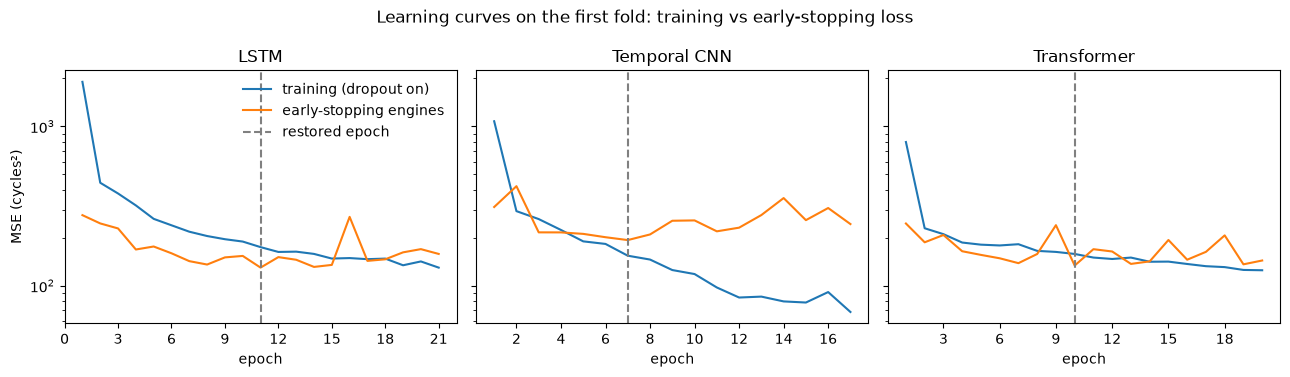

In [9]:
LABELS = {"lstm": "LSTM", "tcn": "Temporal CNN", "transformer": "Transformer"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (name, history) in zip(axes, histories.items()):
    epochs = range(1, len(history["train_loss"]) + 1)
    ax.plot(epochs, history["train_loss"], label="training (dropout on)")
    ax.plot(epochs, history["val_loss"], label="early-stopping engines")
    ax.axvline(history["best_epoch"] + 1, color="grey", linestyle="--", label="restored epoch")
    ax.set(title=LABELS[name], xlabel="epoch", yscale="log")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_ylabel("MSE (cycles²)")
axes[0].legend(frameon=False)
fig.suptitle("Learning curves on the first fold: training vs early-stopping loss")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "dl_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

For the LSTM and the Transformer, the early-stopping loss stops improving at epochs 11 and 10, at 130 and 134. In the ten epochs after that it moves between 131 and 270 for the LSTM and between 136 and 207 for the Transformer, ending at 158 and 144, while the training loss falls slowly, from 175 to 130 and from 158 to 125. Both networks have stopped gaining on unseen engines, but neither shows a sustained rise in early-stopping loss like the temporal CNN's. The training loss probably starts above the early-stopping loss because it is averaged over an epoch in which the weights change quickly, with dropout active.

The temporal CNN does overfit. After its restored epoch 7, its training loss falls from 154 to 68, while its early-stopping loss rises from 193 to between 210 and 355. Dropout of 0.1 does not prevent this; early stopping limits the damage by restoring the epoch-7 weights, from before the early-stopping loss climbs away from the falling training loss. Over all 24 configurations, the mean best epoch lies between 6 and 23 and no fold's best epoch is later than 35, so with a patience of 10 every run stops by epoch 45, well below the 100-epoch limit.

## Summary

- On 30-cycle windows of the 14 sensors, with no engineered features, the Transformer encoder reaches a cross-validation RMSE of 13.28, the lowest of all models in either phase, and the LSTM reaches 14.02, close to XGBoost on engineered features (13.99). The temporal CNN reaches 15.91.
- The networks train on 64 engines per fold rather than Phase 1's 80, because 16 are held out for early stopping, so the comparison with Phase 1 is close but not exactly like for like.
- All three networks beat the Phase 1 models on raw features (16.42 at best), so the sensor history carries information that the current cycle's readings do not.
- The Transformer and the LSTM are most accurate close to failure, with RMSE of 7.98 and 8.84 on cycles with true RUL of at most 50, against 9.88 for XGBoost.
- Early stopping on held-out engines ends every run by epoch 45, with every best epoch at or before 35. On the first fold the LSTM and the Transformer plateau after their best epoch, while the temporal CNN overfits clearly after epoch 7 and early stopping restores its epoch-7 weights.
- The selected configurations and their parameter counts are in `results/dl_best_params.json`, the selected scores in `results/dl_cv.csv`, every searched configuration in `results/dl_search.csv`, and their per-fold scores in `results/dl_folds.csv`.